# Results of the final experiments

Reads the runs submitted by `jobs/run_experiments.sh` (4 conditions × 4 sizes × 3 seeds) and shows:
1. the dev BLEU of every condition and size (mean ± std over seeds),
2. the train and dev loss curves,
3. each condition minus uniform, paired by seed.

```
runs/<condition>_n<size>_seed<seed>/run_info.json   settings + final scores
runs/<condition>_n<size>_seed<seed>/dev_curve.csv   train/dev loss every eval_every steps
```

In [2]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Paths below are relative to the repository root.
if Path.cwd().name == "notebooks":
    os.chdir("..")

RUNS_DIR = Path("runs")
CONDITIONS = ["uniform", "length", "joint", "loss"]
SIZES = ["1000", "2000", "5000", "full"]
COLOUR = {"uniform": "#2a78d6", "length": "#e07b39", "joint": "#3a9e6f", "loss": "#8e5bc4"}

## 1. Load every run

In [3]:
rows = []
for info_file in sorted(RUNS_DIR.glob("*/run_info.json")):
    info = json.loads(info_file.read_text())
    rows.append(
        {
            "condition": info["condition"],
            "size": info["size"],
            "seed": info["seed"],
            "best_step": info["best_step"],
            "steps": info["steps"],
            "dev_loss": info["best_dev_loss"],
            "dev_bleu": info["dev_bleu_greedy"],
            "run_dir": info_file.parent,
        }
    )
runs = pd.DataFrame(rows)
print(f"found {len(runs)} of {len(CONDITIONS) * len(SIZES) * 3} runs")

found 36 of 36 runs


## 2. Dev BLEU

Greedy BLEU on the dev set at the selected checkpoint (lowest dev loss). Mean ± std over the 3 seeds.

In [4]:
stats = runs.groupby(["size", "condition"])["dev_bleu"].agg(["mean", "std"])
table = (stats["mean"].map("{:.2f}".format) + " ± " + stats["std"].map("{:.2f}".format)).unstack()
table.reindex(index=SIZES, columns=CONDITIONS)

condition,uniform,length,joint
size,,,
1000,14.91 ± 0.06,15.02 ± 0.13,14.90 ± 0.11
2000,15.01 ± 0.16,14.91 ± 0.10,14.81 ± 0.17
5000,15.35 ± 0.16,15.17 ± 0.07,15.36 ± 0.16
full,16.16 ± 0.14,16.00 ± 0.08,15.77 ± 0.03


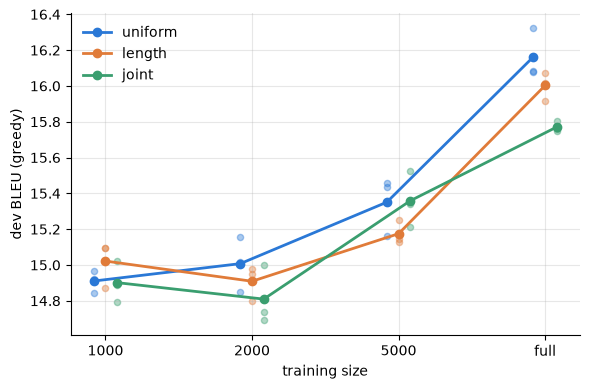

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
x = {size: i for i, size in enumerate(SIZES)}
for k, condition in enumerate(CONDITIONS):
    sub = runs[runs["condition"] == condition]
    offset = (k - (len(CONDITIONS) - 1) / 2) * 0.08  # spread conditions a little so the seed dots don't overlap
    ax.scatter(sub["size"].map(x) + offset, sub["dev_bleu"], color=COLOUR[condition], alpha=0.4, s=20)
    mean = sub.groupby("size")["dev_bleu"].mean().reindex(SIZES)
    ax.plot([x[s] + offset for s in SIZES], mean, "o-", color=COLOUR[condition], linewidth=2, label=condition)
ax.set_xticks(range(len(SIZES)), SIZES)
ax.set_xlabel("training size")
ax.set_ylabel("dev BLEU (greedy)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Loss curves

Rows = size, columns = condition, one pair of lines per seed. Solid = dev loss, dashed = train loss
(averaged over the steps since the previous evaluation). The dot is the selected checkpoint.

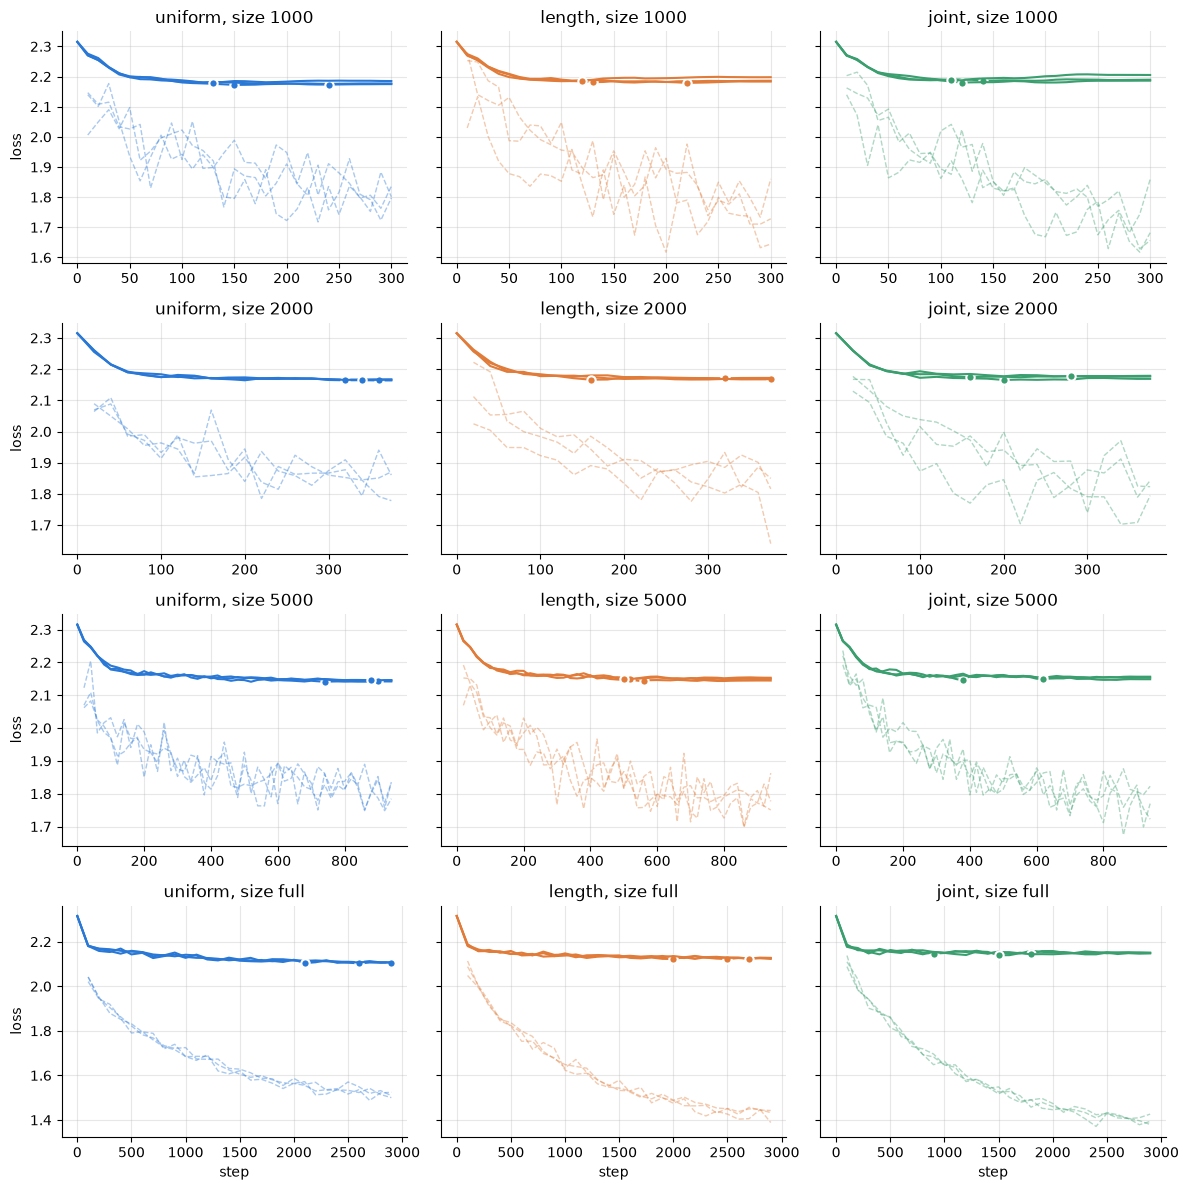

In [6]:
fig, axes = plt.subplots(len(SIZES), len(CONDITIONS), figsize=(4 * len(CONDITIONS), 3 * len(SIZES)),
                         sharey="row", squeeze=False)
for i, size in enumerate(SIZES):
    for j, condition in enumerate(CONDITIONS):
        ax = axes[i, j]
        colour = COLOUR[condition]
        for _, run in runs[(runs["size"] == size) & (runs["condition"] == condition)].iterrows():
            curve = pd.read_csv(run["run_dir"] / "dev_curve.csv")
            ax.plot(curve["step"], curve["train_loss"], "--", color=colour, alpha=0.4, linewidth=1)
            ax.plot(curve["step"], curve["dev_loss"], color=colour, linewidth=1.5)
            ax.plot(run["best_step"], run["dev_loss"], "o", color=colour, markersize=6,
                    markeredgecolor="white", markeredgewidth=1.5)
        ax.set_title(f"{condition}, size {size}")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("step")
for ax in axes[:, 0]:
    ax.set_ylabel("loss")
fig.tight_layout()
plt.show()

## 4. Each condition vs uniform

Same subset and seed, only the sampling weights differ, so the fair comparison is paired:
condition minus uniform for each seed, then mean ± std over the 3 seeds. Positive dev BLEU / negative
dev loss = better than uniform. With 3 seeds, a mean difference smaller than its std is noise.

In [ ]:
base = runs[runs["condition"] == "uniform"].set_index(["size", "seed"])[["dev_bleu", "dev_loss"]]
diffs = []
for condition in CONDITIONS[1:]:
    sub = runs[runs["condition"] == condition].set_index(["size", "seed"])[["dev_bleu", "dev_loss"]]
    d = (sub - base).dropna().reset_index()
    d["condition"] = condition
    diffs.append(d)
diffs = pd.concat(diffs)

for metric, fmt in [("dev_bleu", "{:+.2f}"), ("dev_loss", "{:+.4f}")]:
    s = diffs.groupby(["size", "condition"])[metric].agg(["mean", "std"])
    t = (s["mean"].map(fmt.format) + " ± " + s["std"].map("{:.2f}".format if metric == "dev_bleu" else "{:.4f}".format)).unstack()
    print(f"{metric}: condition minus uniform (mean ± std over seeds)")
    display(t.reindex(index=SIZES, columns=CONDITIONS[1:]))